# Бюджет Еревана: примеры запросов

Примеры работы с базой `data/yerevan_budget.duckdb` (сборка: `make build` или `make download`).
Суммы — в тысячах драмов; данные исполнения — нарастающим итогом с 1 января. Описание таблиц —
[database.md](ru/database.md), словарь данных — [data_dictionary.md](data_dictionary.md).

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
con = duckdb.connect(str(root / "data" / "yerevan_budget.duckdb"), read_only=True)


def q(sql, *args):
    return con.execute(sql, args).df()

## Доходы и расходы по годам

Бюджет (решение Совета старейшин) и факт годового отчёта, млрд драмов.

In [2]:
s = q("""
    SELECT fiscal_year,
           round(revenue_budget_kamd / 1e6, 1) AS revenue_budget,
           round(revenue_actual_kamd / 1e6, 1) AS revenue_actual,
           round(expenditure_budget_kamd / 1e6, 1) AS expenditure_budget,
           round(expenditure_actual_kamd / 1e6, 1) AS expenditure_actual
    FROM v_summary ORDER BY fiscal_year""")
s

,fiscal_year,revenue_budget,revenue_actual,expenditure_budget,expenditure_actual
0,2017,NaN,72.5,NaN,71.0
1,2018,80.2,68.7,80.2,62.8
2,2019,83.1,75.0,84.3,66.8
3,2020,107.1,NaN,116.3,64.3
4,2021,92.4,81.7,100.8,80.4
5,2022,94.6,86.2,98.8,94.8
6,2023,105.1,114.8,105.5,111.2
7,2024,124.6,116.7,124.9,113.7
8,2025,159.4,148.5,159.5,140.8
9,2026,151.5,NaN,156.8,NaN


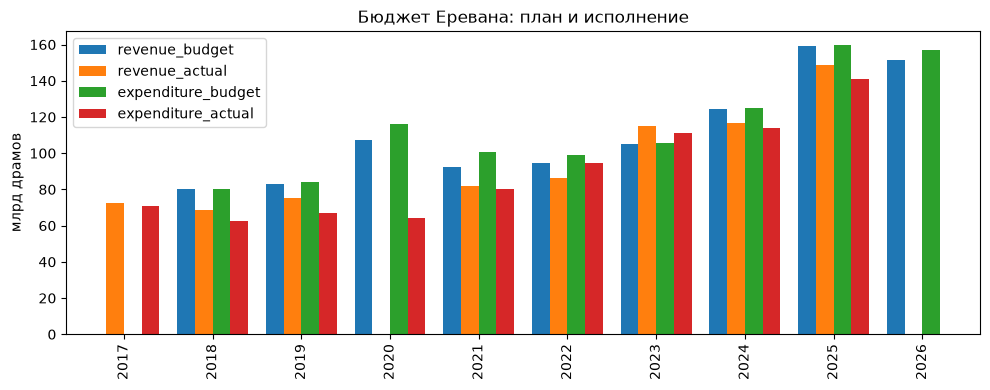

In [3]:
ax = s.set_index("fiscal_year")[["revenue_budget", "revenue_actual", "expenditure_budget", "expenditure_actual"]].plot(
    kind="bar", figsize=(10, 4), width=0.8)
ax.set_ylabel("млрд драмов")
ax.set_xlabel("")
ax.set_title("Бюджет Еревана: план и исполнение")
plt.tight_layout()

## Расходы по функциональным разделам (факт, годовые отчёты), млрд драмов

In [4]:
f = q("""
    SELECT fiscal_year, label_ru AS section, round(sum(actual_total_kamd) / 1e6, 2) AS actual_bn
    FROM v_execution_annual
    WHERE statement = 'expenditure_functional' AND func_code LIKE '%.0.0'
    GROUP BY ALL ORDER BY fiscal_year""")
p = f.pivot_table(index="section", columns="fiscal_year", values="actual_bn", aggfunc="sum")
p.sort_values(p.columns[-1], ascending=False)

fiscal_year,2017,2018,2019,2020,2021,2022,2023,2024,2025
section,,,,,,,,,
Образование,27.86,27.55,28.09,30.58,31.53,35.29,36.48,40.15,46.82
Экономические отношения,9.05,5.57,3.41,2.53,11.78,20.03,28.05,26.92,45.44
Общегосударственные услуги,7.49,7.34,8.41,7.80,9.03,10.40,12.00,12.77,14.78
Охрана окружающей среды,7.58,7.83,9.41,9.64,10.39,12.69,13.58,14.27,13.75
"Отдых, культура и религия",3.68,3.33,3.30,3.13,3.57,4.64,7.34,9.48,9.08
Жилищное строительство и коммунальные услуги,4.34,4.65,5.51,4.89,4.84,6.38,8.99,7.69,7.77
Социальная защита,1.79,1.65,1.44,1.34,1.23,1.34,1.73,1.85,1.47
"Резервные фонды, не отнесенные к основным разделам",8.91,4.69,6.85,4.04,7.63,3.50,1.87,0.08,1.36
Здравоохранение,0.25,0.17,0.30,0.30,0.32,0.39,1.05,0.38,0.31


## Исполнение доходов в 2025 году по основным строкам, млн драмов

In [5]:
q("""
    SELECT line_code, label_ru, round(revised_total_kamd / 1e3) AS revised_mln, round(actual_total_kamd / 1e3) AS actual_mln,
           round(100 * actual_total_kamd / nullif(revised_total_kamd, 0), 1) AS pct
    FROM v_execution_annual
    WHERE fiscal_year = 2025 AND statement = 'revenue'
      AND line_code IN ('1000', '1100', '1110', '1120', '1130', '1140', '1200', '1300', '1340', '1350')
    ORDER BY line_code""")

,line_code,label_ru,revised_mln,actual_mln,pct
0,1000,Всего доходов,147815.0,148518.0,100.5
1,1100,1. Налоги и пошлины,50326.0,57120.0,113.5
2,1110,1.1 Имущественные налоги на недвижимое имущество,19591.0,23039.0,117.6
3,1120,1.2 Имущественные налоги на прочее имущество,13981.0,14419.0,103.1
4,1130,1.3 Местные пошлины,16164.0,18900.0,116.9
5,1140,"1.4 Государственные пошлины, уплачиваемые в бю...",590.0,763.0,129.3
6,1200,2. Официальные гранты,13727.0,13654.0,99.5
7,1300,3. Прочие доходы,83762.0,77744.0,92.8
8,1340,3.4 Доходы бюджета общины от поставки товаров ...,54329.0,47243.0,87.0
9,1350,3.5 Административные сборы,23478.0,25219.0,107.4


## Утверждённый бюджет административных районов (приложение 7), млн драмов

In [6]:
d = q("""
    SELECT fiscal_year, district_en AS district, round(total_kamd / 1e3) AS total_mln
    FROM v_budget_program
    WHERE doc_type = 'budget' AND appendix = 7 AND row_type = 'total' AND district_code <> 'municipality'
    ORDER BY fiscal_year""")
d.pivot_table(index="district", columns="fiscal_year", values="total_mln")

fiscal_year,2018,2019,2020,2021,2022,2023,2024,2025,2026
district,,,,,,,,,
Ajapnyak,2622.0,2681.0,2848.0,2829.0,3101.0,3342.0,3670.0,4048.0,3959.0
Arabkir,2942.0,3059.0,2763.0,2648.0,2837.0,3066.0,3284.0,3723.0,3405.0
Avan,1611.0,1618.0,1336.0,1308.0,1536.0,1525.0,1778.0,2027.0,2138.0
Davtashen,1250.0,1302.0,1366.0,1372.0,1590.0,1660.0,1650.0,1780.0,1780.0
Erebuni,2476.0,2414.0,2222.0,2291.0,2486.0,2620.0,2739.0,3088.0,3031.0
Kanaker-Zeytun,2042.0,2091.0,2057.0,2113.0,2209.0,2418.0,2530.0,2816.0,2903.0
Kentron,3809.0,3839.0,3049.0,3042.0,3381.0,3647.0,3882.0,4606.0,4885.0
Malatia-Sebastia,3071.0,3121.0,2942.0,2930.0,3164.0,3605.0,4065.0,4442.0,4734.0
Nor Nork,3108.0,3203.0,3153.0,2999.0,3410.0,3876.0,4143.0,4513.0,4517.0


## Программный бюджет 2026: крупнейшие программы (город), млн драмов

In [7]:
q("""
    SELECT program_code, program_ru, round(sum(amount_kamd) / 1e3) AS mln
    FROM v_program_budget
    WHERE fiscal_year = 2026 AND doc_type = 'budget_message' AND row_type = 'program' AND district_code IS NULL
    GROUP BY ALL ORDER BY mln DESC LIMIT 15""")

,program_code,program_ru,mln
0,5044,Обеспечение общего образования,23300.0
1,5016,Общественный маршрутный транспорт,21876.0
2,5043,Обеспечение дошкольного образования,16280.0
3,5012,Модернизация и улучшение дорожной инфраструктуры,13613.0
4,5001,Обеспечение осуществления полномочий аппарата ...,13125.0
5,5017,Эксплуатация Ереванского метрополитена и разви...,9560.0
6,5045,Обеспечение внешкольного обучения,8625.0
7,5010,Повышение энергоэффективности общественных зданий,8206.0
8,5026,Вывоз мусора и санитарная очистка,7592.0
9,5034,Благоустройство многоквартирных домов и дворов...,5816.0


## Квартальное исполнение 2026 года, млрд драмов

In [8]:
q("""
    SELECT report_period, statement, round(revised_total_kamd / 1e6, 1) AS revised_bn,
           round(actual_total_kamd / 1e6, 1) AS actual_bn, round(100 * actual_total_kamd / revised_total_kamd, 1) AS pct
    FROM v_execution
    WHERE fiscal_year = 2026
      AND ((statement = 'revenue' AND line_code = '1000') OR (statement = 'expenditure_functional' AND line_code = '2000'))
    ORDER BY statement, report_period""")

,report_period,statement,revised_bn,actual_bn,pct
0,9M,expenditure_functional,180.9,98.5,54.5
1,H1,expenditure_functional,171.9,59.5,34.6
2,Q1,expenditure_functional,169.6,20.9,12.4
3,9M,revenue,163.7,107.5,65.7
4,H1,revenue,154.7,67.3,43.5
5,Q1,revenue,152.4,30.1,19.7


## Полнотекстовый поиск по документам

In [9]:
q("""
    SELECT d.fiscal_year, d.doc_type, t.file_id, t.page
    FROM raw_page_text t JOIN meta_file f USING (file_id) JOIN meta_document d USING (doc_id)
    WHERE t.text ILIKE '%մետրոպոլիտեն%' ORDER BY d.fiscal_year DESC LIMIT 10""")

,fiscal_year,doc_type,file_id,page
0,2027,mtef,38de3df9d8/ԾԲ աղյուսակ 1.pdf,12
1,2027,mtef,38de3df9d8/1 - Ուղերձ 2027-2029.pdf,7
2,2027,mtef,38de3df9d8/1 - Ուղերձ 2027-2029.pdf,14
3,2027,mtef,38de3df9d8/ԾԲ աղյուսակ 2.pdf,8
4,2027,mtef,38de3df9d8/ԾԲ աղյուսակ 2.pdf,7
5,2027,mtef,38de3df9d8/7.pdf,3
6,2027,mtef,38de3df9d8/ԾԲ աղյուսակ 1.pdf,13
7,2026,citizens_budget,22213827b0,5
8,2026,execution_measures,e2534ac753/Երևան քաղաքի 2026 թվականի բյուջեի կ...,10
9,2026,execution_measures,e2534ac753/Երևան քաղաքի 2026 թվականի բյուջեի կ...,5
